# Loading Data

In [1]:
import pandas as pd
df = pd.read_csv("loan data.xls")
df.head(2)

,ID,Asst_Reg,GGGrade,Experience,Validation,Yearly_Income,Home_Status,Unpaid_2_years,Already_Defaulted,Designation,...,File_Status,State,Account_Open,Total_Unpaid_CL,Duration,Unpaid_Amount,Reason,Claim_Type,Due_Fee,Default
0,95074,421802,II,>10yrs,Vfied,633600.0,MORTGAGE,0,0,GLENDALE NISSAN,...,fully paid,California,17,58598.0,3 years,31216.05,debt consolidation,I,0.0,0
1,134131,3964312,IV,7yrs,Source Verified,85483.2,RENT,0,0,Business Teacher,...,whole,NC,15,18924.0,5 years,11660.49,debt consolidation,I,0.0,0


# Data PreProcessing- Data cleaning, Detecting outliers, handling categorical data.


In [225]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 87500 entries, 0 to 87499
Data columns (total 30 columns):
 #   Column               Non-Null Count  Dtype  
---  ------               --------------  -----  
 0   ID                   87500 non-null  int64  
 1   Asst_Reg             87500 non-null  int64  
 2   GGGrade              87500 non-null  object 
 3   Experience           87500 non-null  object 
 4   Validation           87500 non-null  object 
 5   Yearly_Income        81925 non-null  float64
 6   Home_Status          87500 non-null  object 
 7   Unpaid_2_years       87500 non-null  int64  
 8   Already_Defaulted    87500 non-null  int64  
 9   Designation          86086 non-null  object 
 10  Debt_to_Income       84011 non-null  float64
 11  Postal_Code          86111 non-null  float64
 12  Lend_Amount          87500 non-null  float64
 13  Deprecatory_Records  87500 non-null  int64  
 14  Interest_Charged     87500 non-null  float64
 15  Usage_Rate           87500 non-null 

In [226]:
df.isnull().sum()

,0
ID,0
Asst_Reg,0
GGGrade,0
Experience,0
Validation,0
Yearly_Income,5575
Home_Status,0
Unpaid_2_years,0
Already_Defaulted,0
Designation,1414


In [227]:
df['Yearly_Income'] = df['Yearly_Income'].fillna(df['Yearly_Income'].mean())
df['Designation']= df['Designation'].fillna('unknown')
df['Debt_to_Income'] = df['Debt_to_Income'].fillna(df['Debt_to_Income'].mean())
df['Total_Unpaid_CL'] = df['Total_Unpaid_CL'].fillna(df['Total_Unpaid_CL'].mode()[0])


In [228]:
df.isnull().sum()

,0
ID,0
Asst_Reg,0
GGGrade,0
Experience,0
Validation,0
Yearly_Income,0
Home_Status,0
Unpaid_2_years,0
Already_Defaulted,0
Designation,0


In [229]:
df=df.dropna()
df.isnull().sum()

,0
ID,0
Asst_Reg,0
GGGrade,0
Experience,0
Validation,0
Yearly_Income,0
Home_Status,0
Unpaid_2_years,0
Already_Defaulted,0
Designation,0


In [230]:
df=df.reset_index(drop = True)


In [231]:
df.duplicated().sum()

np.int64(0)

In [232]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 81351 entries, 0 to 81350
Data columns (total 30 columns):
 #   Column               Non-Null Count  Dtype  
---  ------               --------------  -----  
 0   ID                   81351 non-null  int64  
 1   Asst_Reg             81351 non-null  int64  
 2   GGGrade              81351 non-null  object 
 3   Experience           81351 non-null  object 
 4   Validation           81351 non-null  object 
 5   Yearly_Income        81351 non-null  float64
 6   Home_Status          81351 non-null  object 
 7   Unpaid_2_years       81351 non-null  int64  
 8   Already_Defaulted    81351 non-null  int64  
 9   Designation          81351 non-null  object 
 10  Debt_to_Income       81351 non-null  float64
 11  Postal_Code          81351 non-null  float64
 12  Lend_Amount          81351 non-null  float64
 13  Deprecatory_Records  81351 non-null  int64  
 14  Interest_Charged     81351 non-null  float64
 15  Usage_Rate           81351 non-null 

In [233]:
# columns to drop instantly which don't have any impact on prediction
df = df.drop(['ID', 'Asst_Reg'], axis = 1)

# Handling categorical columns

In [234]:
categorical_columns = ['GGGrade', 'Experience', 'Validation', 'Home_Status', 'Designation', 'File_Status', 'State', 'Duration', 'Reason', 'Claim_Type']

In [235]:
for col in categorical_columns:
    print(f"\n{col}:")
    print("Unique Count:", df[col].nunique())
    print("Unique Values:", df[col].unique())
    print("Data Type:", df[col].dtype)



GGGrade:
Unique Count: 7
Unique Values: ['II' 'IV' 'III' 'V' 'VII' 'VI' 'I']
Data Type: object

Experience:
Unique Count: 11
Unique Values: ['>10yrs' '7yrs' '<1yr' '2yrs' '1yrs' '4yrs' '9yrs' '6yrs' '5yrs' '8yrs'
 '3yrs']
Data Type: object

Validation:
Unique Count: 3
Unique Values: ['Vfied' 'Source Verified' 'Not Vfied']
Data Type: object

Home_Status:
Unique Count: 5
Unique Values: ['MORTGAGE' 'RENT' 'OWN' 'OTHER' 'NONE']
Data Type: object

Designation:
Unique Count: 37933
Unique Values: ['GLENDALE NISSAN' 'Business Teacher' 'driver' ... 'Interface Coordinator'
 'PARTS CLERK' 'Outside sales rep']
Data Type: object

File_Status:
Unique Count: 2
Unique Values: ['fully paid' 'whole']
Data Type: object

State:
Unique Count: 49
Unique Values: ['California' 'NC' 'Florida' 'NewJersey' 'LA' 'TX' 'CT' 'MI' 'OR' 'AR'
 'Newyork' 'MT' 'CO' 'Ohio' 'MN' 'GA' 'Maryland' 'AL' 'SC' 'PA' 'AZ' 'UT'
 'MA' 'VA' 'IL' 'WI' 'NV' 'HI' 'RI' 'TN' 'WA' 'VT' 'OK' 'IN' 'AK' 'NE'
 'NH' 'MO' 'WV' 'MS' 'KY' 'KS' 'D

In [236]:
# symbols removing: Duration, Experience
# Label Encoding Features: GGGrade
# One Hot Encoding Features: Claim_Type, Reason, State, File Status, Designation, Home_Status, Validation.


In [237]:
# drop categorical data columns that has high number of unique values( generally>50) whiile doing one hot encoding
# categorical columns to drop = Designation, state,
df = df.drop(['Designation', 'State'], axis = 1),

In [238]:
# symbols removing: Duration, Experience
df = df[0] # Correcting 'df' from tuple to DataFrame
df['Experience'] = (df['Experience'].str.replace(r'>|<|yrs|yr', '', regex=True).str.strip().astype(int))
df['Duration'] = (df['Duration'].str.replace(r'years', '', regex=True).str.strip().astype(int))

In [239]:
df['GGGrade'].unique()

array(['II', 'IV', 'III', 'V', 'VII', 'VI', 'I'], dtype=object)

In [240]:
# Label Encoding Features: GGGrade
grade_mapping = {
    'I': 1,
    'II': 2,
    'III': 3,
    'IV': 4,
    'V': 5,
    'VI': 6,
    'VII': 7
}

# Apply mapping
df['encoded_GGGrade'] = df['GGGrade'].map(grade_mapping)

In [241]:
df = df.drop('GGGrade', axis=1)  # axis=1 → drop column

In [242]:
df.shape

(81351, 26)

In [243]:
# One Hot Encoding Features: Claim_Type, Reason, State, File Status, Designation, Home_Status, Validation.

# List of categorical features to one-hot encode
categorical_features = ['Claim_Type', 'Reason', 'File_Status', 'Home_Status', 'Validation']

# Using pandas.get_dummies
df = pd.get_dummies(df, columns=categorical_features)

In [244]:
df.shape

(81351, 46)

# Exploratory Data Analysis (EDA)

In [245]:
#correlation Analysis:
'''
since it is binary classification problem we use mutual information method to see the linear and non-linear relationship between features and target.
'''

from sklearn.feature_selection import mutual_info_classif
import pandas as pd

X = df.drop('Default', axis=1)
y = df['Default']

mi = mutual_info_classif(X, y)
mi_scores = pd.Series(mi, index=X.columns).sort_values(ascending=False)

print(mi_scores)


File_Status_whole             0.021267
File_Status_fully paid        0.015777
Claim_Type_I                  0.013037
Reason_debt  consolidation    0.012177
Duration                      0.012085
Validation_Source Verified    0.009640
Home_Status_MORTGAGE          0.008274
Lend_Amount                   0.006363
Home_Status_RENT              0.006055
Experience                    0.005650
Inquiries                     0.005399
Gross_Collection              0.005359
Validation_Not Vfied          0.004941
Validation_Vfied              0.004274
Debt_to_Income                0.003434
Account_Open                  0.002995
Unpaid_Amount                 0.002835
Reason_credit  card           0.002505
encoded_GGGrade               0.002462
Reason_car                    0.002015
Usage_Rate                    0.001961
Present_Balance               0.001734
Interest_Charged              0.001513
Reason_major  purchase        0.001436
Home_Status_NONE              0.001263
Reason_medical           

In [246]:
# Drop features with zero mutual information
selected_features = mi_scores[mi_scores > 0].index

# Create new dataframe with only selected features and make sure it's a copy
X = X[selected_features].copy()

# Detecting Outliers using Box PLot Method

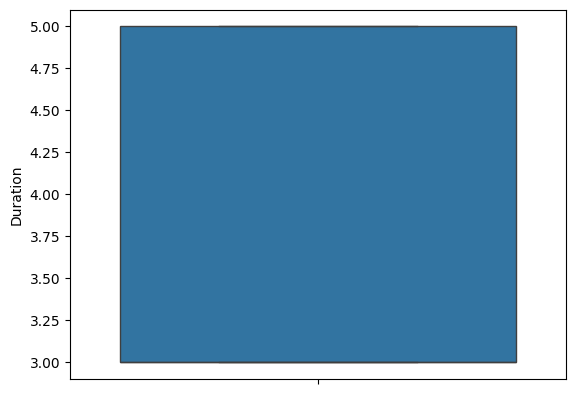

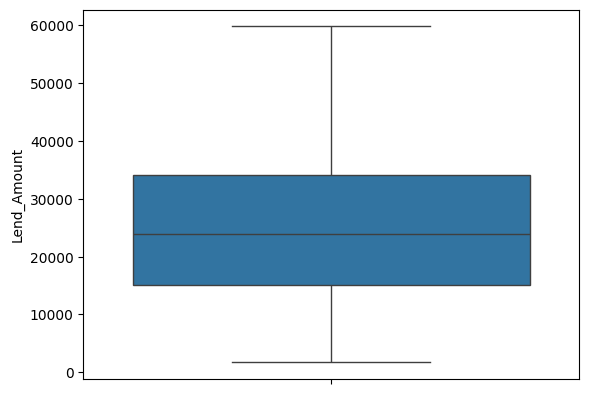

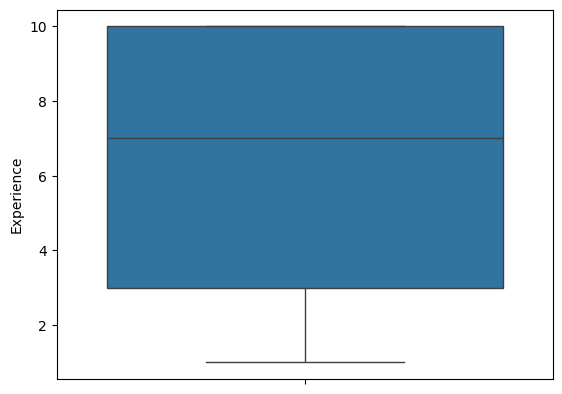

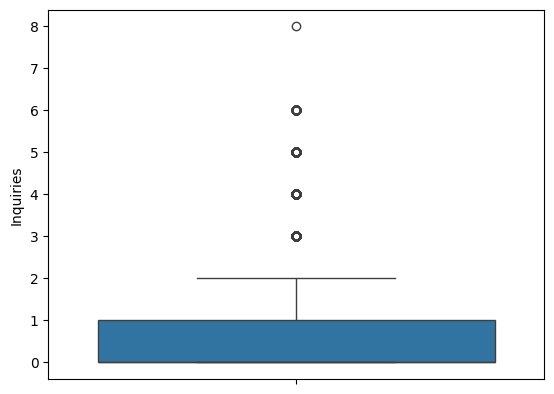

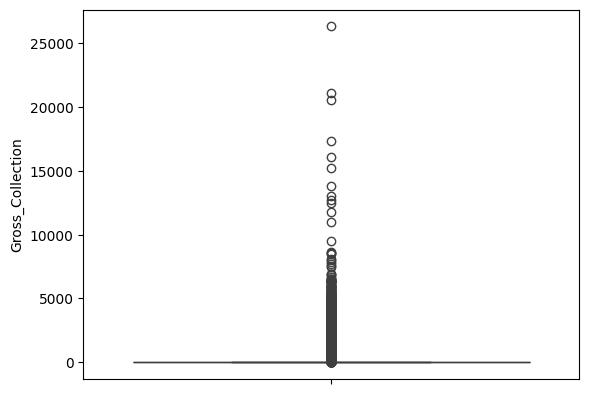

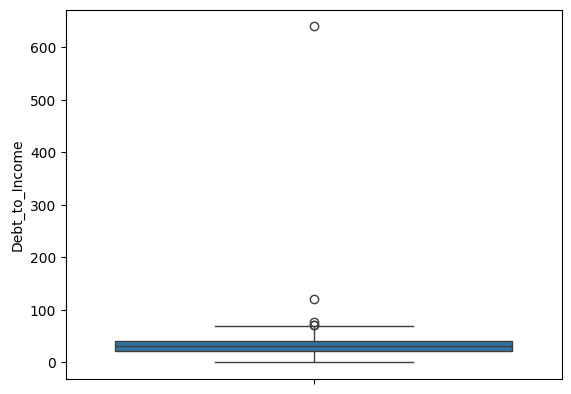

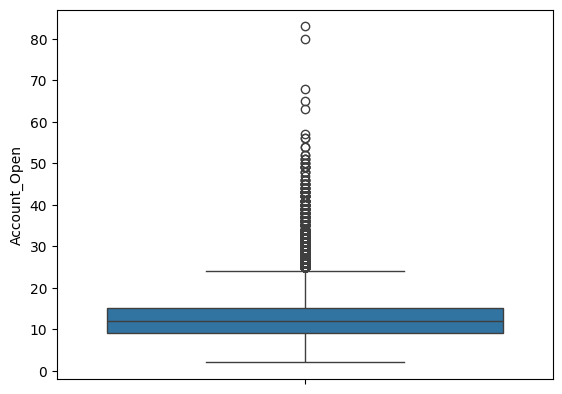

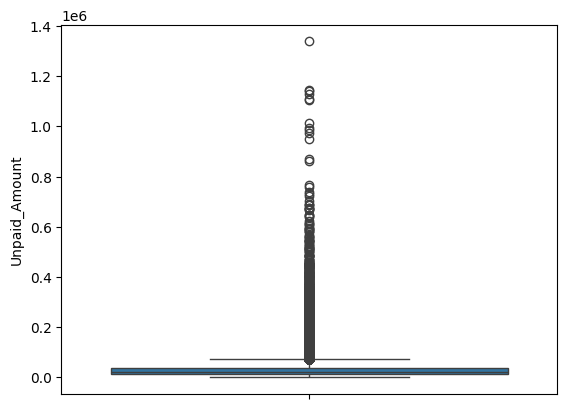

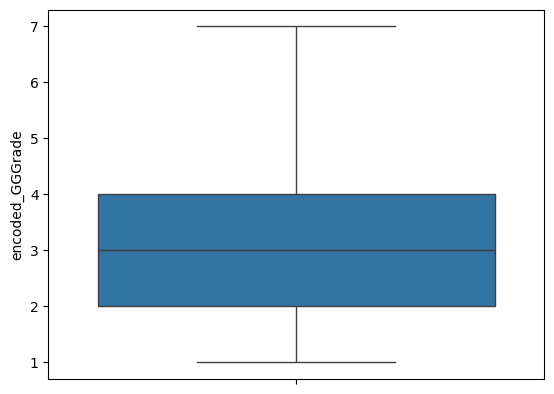

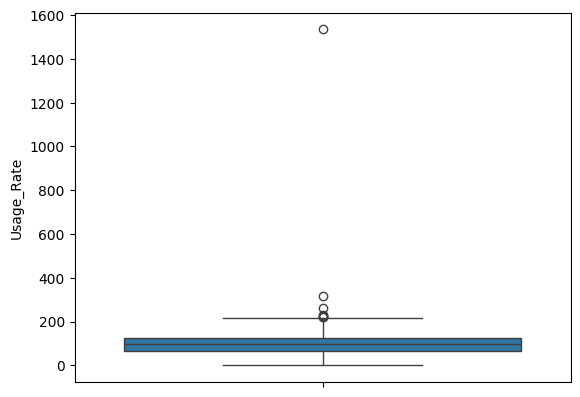

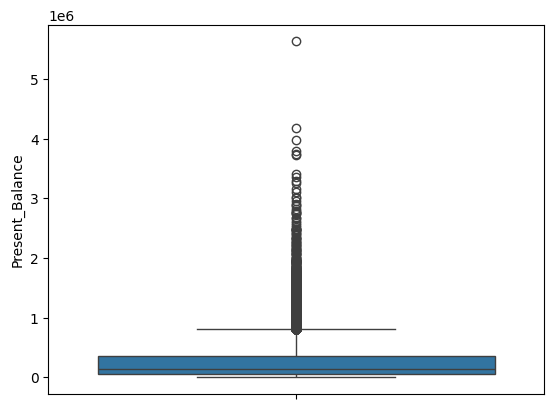

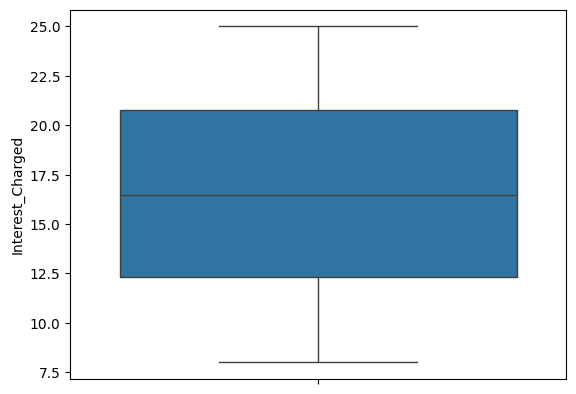

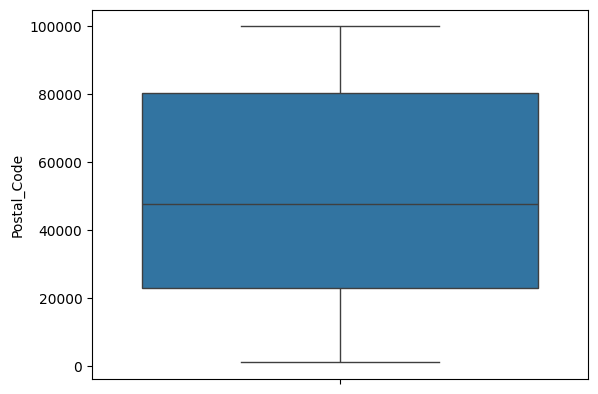

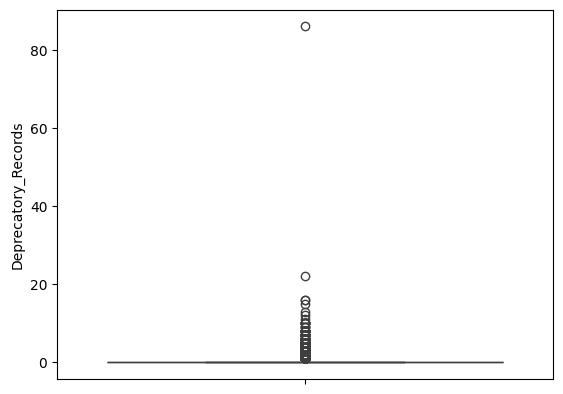

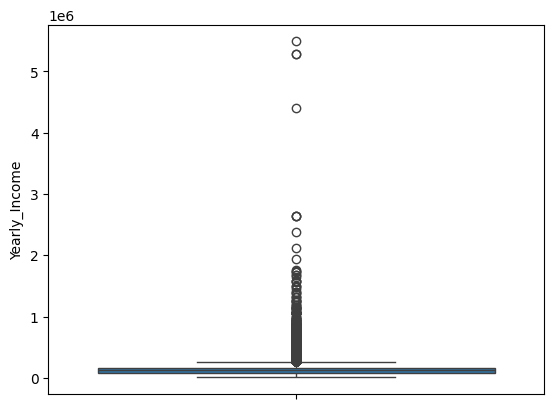

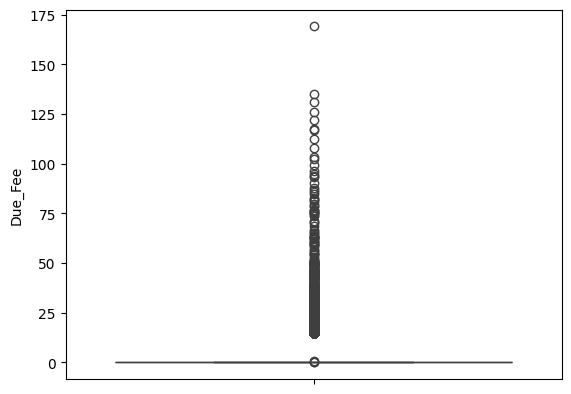

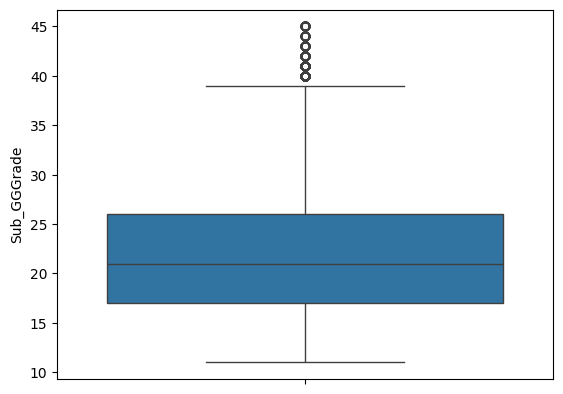

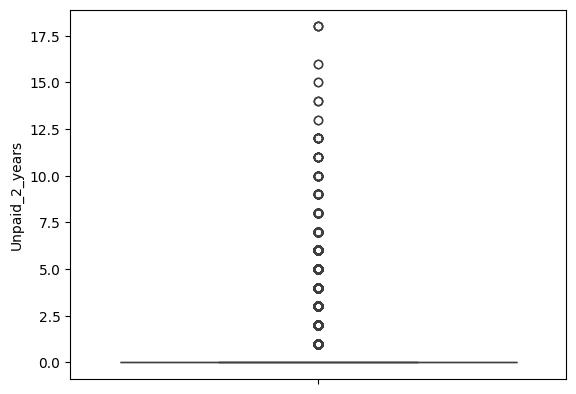

In [247]:
import seaborn as sns
import matplotlib.pyplot as plt

for col in X.select_dtypes(include=['int','float64']).columns:
    sns.boxplot(data = X[col])
    plt.show()


# Handling Outliers 

In [275]:
import numpy as np
numeric_columns = X.select_dtypes(include=['int', 'float64']).columns

for col in numeric_columns:
    Q1 = df[col].quantile(0.25)
    Q3 = df[col].quantile(0.75)
    IQR = Q3 - Q1

    lower_bound = Q1 - 1.5 * IQR
    upper_bound = Q3 + 1.5 * IQR
    print(f"{col}: {lower_bound}----{upper_bound}")


    # Capping
    X[col] = np.where(df[col] > upper_bound, upper_bound,
                       np.where(df[col] < lower_bound, lower_bound, df[col]))

Duration: 0.0----8.0
Lend_Amount: -13680.0----62928.0
Experience: -7.5----20.5
Inquiries: -1.5----2.5
Debt_to_Income: -8.500799999999998----69.72
Account_Open: 0.0----24.0
Unpaid_Amount: -26074.935----73987.425
encoded_GGGrade: -1.0----7.0
Usage_Rate: -24.768----217.40800000000002
Present_Balance: -400918.57----806144.07
Interest_Charged: -0.37999999999999723----33.459999999999994
Postal_Code: -63050.0----166150.0
Yearly_Income: -22000.0----266640.0
Sub_GGGrade: 3.5----39.5


# Split the data into training and testing sets

In [250]:
from sklearn.model_selection import train_test_split
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)


# Scaling

In [2]:
from sklearn.linear_model import LogisticRegression
from sklearn.preprocessing import StandardScaler # Added for scaling

# Scale the data first, as both models will likely benefit
scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)


NameError: name 'X_train' is not defined

# Train Logistic Regression model

In [ ]:
# Train Logistic Regression model (l)
model1 = LogisticRegression(max_iter=1000) # Added max_iter as per previous fix
model1.fit(X_train_scaled, y_train)

# Predict on test set

In [252]:
X_test_scaled = scaler.transform(X_test)
y_pred1 = model1.predict(X_test_scaled)

In [253]:
df['Default'].value_counts()

,count
Default,
0,65984
1,15367


# Confusion Matrix and Classification Report

In [254]:
from sklearn.metrics import accuracy_score, classification_report, confusion_matrix

cm1 = confusion_matrix(y_test, y_pred1)
print(cm1)

[[13315     8]
 [ 2939     9]]


<Axes: >

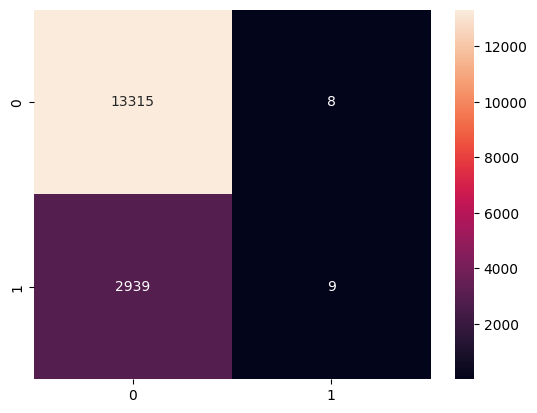

In [255]:
import seaborn as sns

sns.heatmap(cm1, annot = True, fmt = "d")



In [256]:
print(accuracy_score(y_test,y_pred1))

0.8188802163358122


In [257]:
# classification report:
print(classification_report(y_test, y_pred1))

              precision    recall  f1-score   support

           0       0.82      1.00      0.90     13323
           1       0.53      0.00      0.01      2948

    accuracy                           0.82     16271
   macro avg       0.67      0.50      0.45     16271
weighted avg       0.77      0.82      0.74     16271



In [258]:
import pandas as pd

# Ensure X has the same features as the model was trained on
# Re-apply feature selection based on mutual information scores, as X in current state has extra columns.
# From the kernel state, mi_scores has been computed and selected_features was the index of mi_scores > 0.
# We need to ensure X reflects these selected features.

# Assuming `selected_features` was correctly derived earlier and contains the 33 feature names.
# If `selected_features` is not available, we would need to re-compute it or use X_train.columns

# Let's assume 'model1' is the intended model based on previous execution cells.

# Filter X to only include the features model1 was trained on
# We can get the feature names model1 was trained on from X_train.columns
X = X[X_train.columns]

# Create a DataFrame to store feature names and their coefficients
coef_df = pd.DataFrame({
    'Feature': X.columns,
    'Importance': model1.coef_[0]
})

# Sort features by the absolute value of their importance for better visualization
coef_df = coef_df.reindex(coef_df['Importance'].abs().sort_values(ascending=False).index)

print("Feature Importances (Logistic Regression Coefficients):")
print(coef_df)

Feature Importances (Logistic Regression Coefficients):
                       Feature  Importance
14              Debt_to_Income   -0.212827
4                     Duration   -0.203049
1       File_Status_fully paid    0.171074
0            File_Status_whole   -0.171074
10                   Inquiries    0.156540
2                 Claim_Type_I    0.133129
5   Validation_Source Verified   -0.126286
32                 Sub_GGGrade    0.112200
18             encoded_GGGrade   -0.098673
13            Validation_Vfied    0.090389
3   Reason_debt  consolidation    0.087491
26                 Postal_Code    0.083932
21             Present_Balance    0.081685
7                  Lend_Amount   -0.077181
24            Home_Status_NONE    0.058285
20                  Usage_Rate   -0.055082
12        Validation_Not Vfied    0.043872
17         Reason_credit  card    0.036729
31             Home_Status_OWN   -0.034698
28      Reason_small  business   -0.030009
15                Account_Open   -0.02587

In [263]:
X = X.drop(['Gross_Collection', 'Due_Fee', 'Deprecatory_Records', 'Unpaid_2_years'], axis = 1)

In [264]:
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)
# Scale the data first, as both models will likely benefit
scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)

# Train Logistic Regression model (l)
model2 = LogisticRegression(max_iter=1000) # Added max_iter as per previous fix
model2.fit(X_train_scaled, y_train)


LogisticRegression(max_iter=1000)

In [265]:
X_test_scaled = scaler.transform(X_test)

# And then make predictions
y_pred2 = model2.predict(X_test_scaled)

In [266]:
cm2 = confusion_matrix(y_test, y_pred2)
print(cm2)

[[13315     8]
 [ 2939     9]]
